# 10_01 The Confusion Matrix from Two Score Distributions

**Learning objectives**
- See every binary classifier as **two overlapping score distributions** (positives and negatives) and a **threshold**; read the four cells of the **confusion matrix** (TP, FP, TN, FN) as areas under those distributions.
- Derive the **true and false positive rates** for Gaussian scores, $\mathrm{TPR}=1-\Phi\!\big(\tfrac{t-\mu_1}{\sigma}\big)$ and $\mathrm{FPR}=1-\Phi\!\big(\tfrac{t-\mu_0}{\sigma}\big)$, and the separability index $d'=(\mu_1-\mu_0)/\sigma$.
- Turn rates into **expected counts** with the **prevalence**, and compute **precision (PPV)** with Bayes' rule; see why a good classifier can still have poor precision when the positive class is rare.
- Estimate the confusion matrix from data (with **Wilson intervals**), and check the theory by simulation and on real **SMS spam scores**.

**Prerequisites:** [00_05 Bayes' rule](../../module_00_foundations/notebooks/00_05_bayes_theorem.ipynb), [02_05 Normal distribution](../../module_02_continuous/notebooks/02_05_normal.ipynb), [06_03 Hypothesis testing](../../module_06_inference/notebooks/06_03_hypothesis_testing_core.ipynb) (type I and II errors), [09_03 Naive Bayes](../../module_09_probabilistic_models/notebooks/09_03_naive_bayes.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A hypothesis test rejects when a statistic exceeds a threshold; the **type I error** is a false alarm and the **type II error** a miss (06_03). The standard normal CDF is $\Phi$. Bayes' rule turns $P(\text{score}\mid\text{class})$ into $P(\text{class}\mid\text{score})$ using the prior (00_05). A proportion estimated from $n$ cases has a binomial standard error $\sqrt{p(1-p)/n}$.

## 3. Intuition and story
Every classifier, from a logistic regression to a large neural network, ends in a single number per case: a **score**. A fraud model says 0.83 for one transaction and 0.12 for another. To act we need a **decision**, so we pick a threshold: flag everything above it. Genuine cases tend to have low scores and fraudulent cases high scores, but the two groups **overlap**: some genuine transactions look suspicious and some frauds look innocent. The confusion matrix just counts what falls on each side of the threshold. Moving the threshold slides a vertical line across two overlapping bell curves: more frauds are caught but more genuine customers are bothered. All the metrics of the next lessons (precision, recall, ROC, F1) are different ways of reading this one picture.

## 4. Formal definitions

Class $Y\in\{0,1\}$ (1 = positive, e.g. fraud), prevalence $\pi=P(Y=1)$, a score $S$ with class-conditional distributions $f_1$ (positives) and $f_0$ (negatives). The classifier predicts positive if $S>t$.

| | Predicted positive ($S>t$) | Predicted negative ($S\le t$) |
|---|---|---|
| **Actually positive** | TP: $\pi\,P(S>t\mid1)$ | FN: $\pi\,P(S\le t\mid1)$ |
| **Actually negative** | FP: $(1-\pi)P(S>t\mid0)$ | TN: $(1-\pi)P(S\le t\mid0)$ |

| Rate | Definition |
|---|---|
| **TPR** (sensitivity, recall) | $P(S>t\mid Y=1)=\dfrac{TP}{TP+FN}$ |
| **FPR** | $P(S>t\mid Y=0)=\dfrac{FP}{FP+TN}$, specificity $=1-\mathrm{FPR}$ |
| **PPV** (precision) | $P(Y=1\mid S>t)=\dfrac{TP}{TP+FP}=\dfrac{\pi\,\mathrm{TPR}}{\pi\,\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$ |
| **NPV** | $P(Y=0\mid S\le t)=\dfrac{TN}{TN+FN}$ |
| **Gaussian scores** | $S\mid1\sim N(\mu_1,\sigma^2)$, $S\mid0\sim N(\mu_0,\sigma^2)$, $d'=(\mu_1-\mu_0)/\sigma$ |

## 5. Derivations

### 5.1 The four cells are tail areas
$P(S>t\mid Y=1)=\int_t^\infty f_1(s)\,ds=1-F_1(t)$ and $P(S>t\mid Y=0)=1-F_0(t)$. For Gaussian scores with equal variance $F_c(t)=\Phi\big(\frac{t-\mu_c}\sigma\big)$, so $\mathrm{TPR}(t)=1-\Phi\big(\frac{t-\mu_1}\sigma\big)$ and $\mathrm{FPR}(t)=1-\Phi\big(\frac{t-\mu_0}\sigma\big)$. **In plain words.** The true positive rate is the share of the positive curve to the right of the threshold, the false positive rate the share of the negative curve to the right.

### 5.2 The threshold trade-off
Raising $t$ lowers both rates. The slope of the TPR-FPR relationship at threshold $t$ is the likelihood ratio $f_1(t)/f_0(t)$, which for equal-variance Gaussians equals $\exp\{d'(t-\mu_0)/\sigma-d'^2/2\}$, increasing in $t$. **In plain words.** The more suspicious a score is, the more strongly it favours "positive": at a high threshold each additional false alarm you accept buys little extra recall.

### 5.3 Prevalence enters only through the counts and the PPV
TPR and FPR are properties of the classifier; the *counts* and the *predictive values* depend on how many positives there are: $\mathrm{TP}=N\pi\,\mathrm{TPR}$, $\mathrm{FP}=N(1-\pi)\mathrm{FPR}$, and $\mathrm{PPV}=\dfrac{\pi\mathrm{TPR}}{\pi\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$. **In plain words.** If one case in a thousand is positive, even a classifier that wrongly flags only 1 % of the negatives produces about ten false alarms for every real hit, however good the recall.

### 5.3b Accuracy hides the trade-off
$\mathrm{accuracy}=\pi\,\mathrm{TPR}+(1-\pi)(1-\mathrm{FPR})$. With $\pi=0.01$ a classifier that never flags anyone has accuracy 0.99. **In plain words.** On rare events accuracy mostly measures how rare the events are.

### 5.4 Estimating the cells and their uncertainty
From $n_1$ positives and $n_0$ negatives, $\widehat{\mathrm{TPR}}=\frac{TP}{n_1}$ is a binomial proportion with standard error $\sqrt{\mathrm{TPR}(1-\mathrm{TPR})/n_1}$. The **Wilson interval** $\dfrac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}n+\frac{z^2}{4n^2}}}{1+z^2/n}$ has better coverage than the Wald interval near 0 or 1. **In plain words.** The rates of a classifier are estimated from a small number of positives, so with 20 positives a recall of 0.90 could easily be anywhere from 0.70 to 0.97.

### 5.5 Separability
For equal-variance Gaussians the whole family of confusion matrices is governed by $d'$ and the threshold: at the midpoint threshold $t=(\mu_0+\mu_1)/2$, $\mathrm{TPR}=1-\mathrm{FPR}=\Phi(d'/2)$: $d'=1$ gives 69 %, $d'=2$ gives 84 %, $d'=3$ gives 93 %. **In plain words.** $d'$ is the distance between the two groups' average scores measured in standard deviations; the larger it is, the less the curves overlap.

## 6. Properties and relationships
- **TPR and FPR are conditional on the true class** and do not depend on the prevalence; PPV, NPV, accuracy and the counts do.
- **Type I and type II errors** of a hypothesis test are the FPR and $1-$TPR of a classifier whose score is the test statistic (06_03); the p-value threshold is the decision threshold.
- **Any monotone transformation of the score** gives the same family of confusion matrices (only the labels of the thresholds change): what matters is the ranking.
- **The overlap is the irreducible part:** no threshold can have both a TPR near 1 and an FPR near 0 unless $d'$ is large.
- **Link to ML and AI:** the output of every classifier (probability, logit, margin); medical screening, spam filters, fraud and abuse detection, content moderation, and safety classifiers for language models; the next lessons build metrics, ROC curves and decision rules on this picture.

## 7. Helpers

Theoretical rates and counts for Gaussian scores, empirical confusion counts from labelled scores, and the Wilson interval.

In [2]:
def rates(t, mu0=0.0, mu1=2.0, s0=1.0, s1=1.0): return stats.norm.sf(t, mu1, s1), stats.norm.sf(t, mu0, s0)        # TPR, FPR
def cm_theory(t, N=100_000, pi=0.1, **kw): tpr, fpr = rates(t, **kw); return np.array([[N * pi * tpr, N * pi * (1 - tpr)], [N * (1 - pi) * fpr, N * (1 - pi) * (1 - fpr)]])  # rows: actual pos, actual neg; cols: pred pos, pred neg
def cm_emp(score, y, t): p = score > t; return np.array([[np.sum(p & (y == 1)), np.sum(~p & (y == 1))], [np.sum(p & (y == 0)), np.sum(~p & (y == 0))]])
def wilson(k, n, z=1.96): p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n); return c - h, c + h
def ppv(tpr, fpr, pi): return pi * tpr / (pi * tpr + (1 - pi) * fpr)
M = cm_theory(1.0); print("expected confusion matrix, N = 100,000, prevalence 0.10, d' = 2, threshold 1:\n", M.round(1), "\nTPR, FPR:", [round(float(v), 4) for v in rates(1.0)], "| PPV:", round(float(ppv(*rates(1.0), 0.1)), 4), "| accuracy:", round(float((M[0, 0] + M[1, 1]) / M.sum()), 4))
print("Wilson interval for 18 of 20:", np.round(wilson(18, 20), 3), "| Wald interval:", np.round(0.9 + np.array([-1, 1]) * 1.96 * np.sqrt(0.9 * 0.1 / 20), 3))
assert abs(M.sum() - 100_000) < 1e-6 and abs(rates(1.0)[0] - 0.8413) < 1e-4 and abs(rates(1.0)[1] - 0.1587) < 1e-4 and abs(wilson(18, 20)[0] - 0.699) < 0.005

expected confusion matrix, N = 100,000, prevalence 0.10, d' = 2, threshold 1:
 [[ 8413.4  1586.6]
 [14279.  75721. ]] 
TPR, FPR: [0.8413, 0.1587] | PPV: 0.3708 | accuracy: 0.8413
Wilson interval for 18 of 20: [0.699 0.972] | Wald interval: [0.769 1.031]


## 8. 2D visuals

### 8.1 The two score distributions and a threshold
Negatives $N(0,1)$ and positives $N(2,1)$ ($d'=2$), prevalence 10 %. The threshold $t=1$ splits each bell curve in two: the shaded regions are TP (positives above $t$), FN (positives below), FP (negatives above) and TN (negatives below). Curves are scaled by the class sizes so that areas are counts.

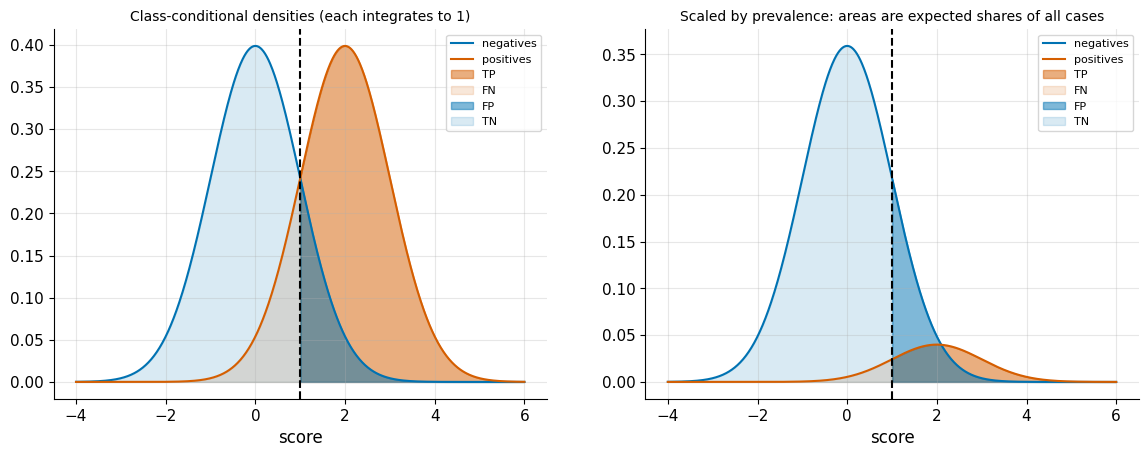

TPR 0.8413, FPR 0.1587, PPV 0.3708; shares of all cases: TP 0.0841, FN 0.0159, FP 0.1428, TN 0.7572 (sum 1.0)


In [3]:
xg = np.linspace(-4, 6, 800); pi = 0.1; t = 1.0; fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, scale, ttl in [(axes[0], False, "Class-conditional densities (each integrates to 1)"), (axes[1], True, "Scaled by prevalence: areas are expected shares of all cases")]:
    d0 = stats.norm.pdf(xg, 0, 1) * ((1 - pi) if scale else 1); d1 = stats.norm.pdf(xg, 2, 1) * (pi if scale else 1)
    ax.plot(xg, d0, color=MAIN, label="negatives"); ax.plot(xg, d1, color=HIGHLIGHT, label="positives"); ax.fill_between(xg, d1, where=xg > t, color=HIGHLIGHT, alpha=0.5, label="TP"); ax.fill_between(xg, d1, where=xg <= t, color=HIGHLIGHT, alpha=0.15, label="FN"); ax.fill_between(xg, d0, where=xg > t, color=MAIN, alpha=0.5, label="FP"); ax.fill_between(xg, d0, where=xg <= t, color=MAIN, alpha=0.15, label="TN"); ax.axvline(t, color="black", linestyle="--"); ax.set_xlabel("score"); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
plt.show(); tpr, fpr = rates(t); print(f"TPR {tpr:.4f}, FPR {fpr:.4f}, PPV {ppv(tpr, fpr, pi):.4f}; shares of all cases: TP {pi * tpr:.4f}, FN {pi * (1 - tpr):.4f}, FP {(1 - pi) * fpr:.4f}, TN {(1 - pi) * (1 - fpr):.4f} (sum {pi * tpr + pi * (1 - tpr) + (1 - pi) * fpr + (1 - pi) * (1 - fpr):.1f})"); assert abs(np.trapezoid(stats.norm.pdf(xg, 2, 1)[xg > t], xg[xg > t]) - tpr) < 3e-3

### 8.2 Three thresholds, three confusion matrices
The expected matrices for $N=100,000$ cases at $t=0$, $1$ and $2$: a low threshold catches almost every positive but floods the analysts with false alarms; a high threshold does the reverse.

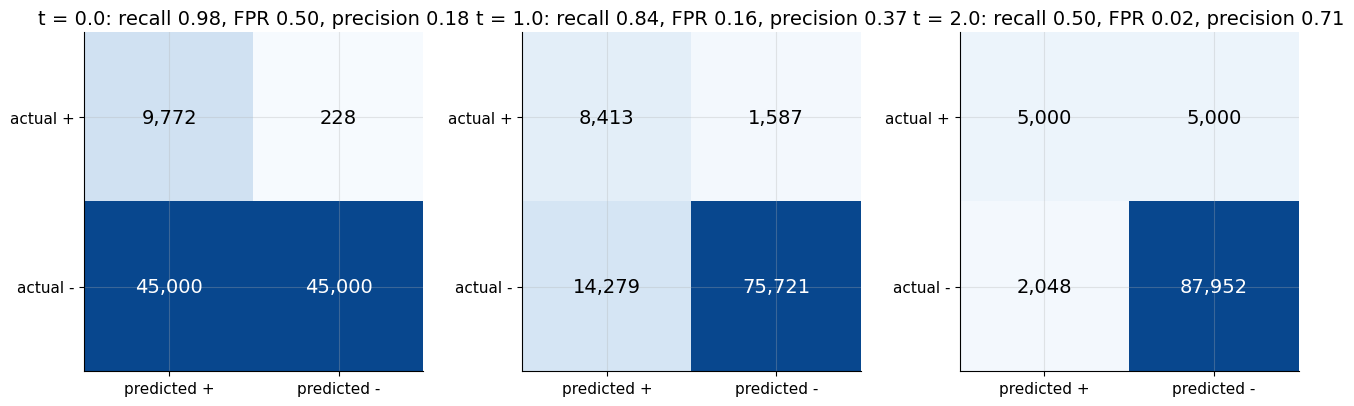

{0.0: (9772, 45000), 1.0: (8413, 14279), 2.0: (5000, 2048)} (TP, FP) at t = 0, 1, 2


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4)); mats = {}
for ax, t_ in zip(axes, (0.0, 1.0, 2.0)):
    Mt = cm_theory(t_); mats[t_] = Mt; ax.imshow(Mt, cmap="Blues", vmin=0, vmax=Mt.max() * 1.1); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["predicted +", "predicted -"]); ax.set_yticklabels(["actual +", "actual -"])
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{Mt[i, j]:,.0f}", ha="center", va="center", fontsize=14, color="white" if Mt[i, j] > Mt.max() / 2 else "black")
    tp_, fp_ = rates(t_); ax.set_title(f"t = {t_}: recall {tp_:.2f}, FPR {fp_:.2f}, precision {ppv(tp_, fp_, 0.1):.2f}")
plt.show(); print({t_: (int(round(m_[0, 0])), int(round(m_[1, 0]))) for t_, m_ in mats.items()}, "(TP, FP) at t = 0, 1, 2"); assert mats[0.0][0, 0] > mats[1.0][0, 0] > mats[2.0][0, 0] and mats[0.0][1, 0] > mats[1.0][1, 0] > mats[2.0][1, 0]

### 8.3 Rates against the threshold, and the effect of separability
Left: TPR and FPR as functions of $t$ for $d'=2$. Right: the TPR at a fixed FPR of 5 % for several $d'$: the better the separation, the more positives are caught at the same false-alarm rate.

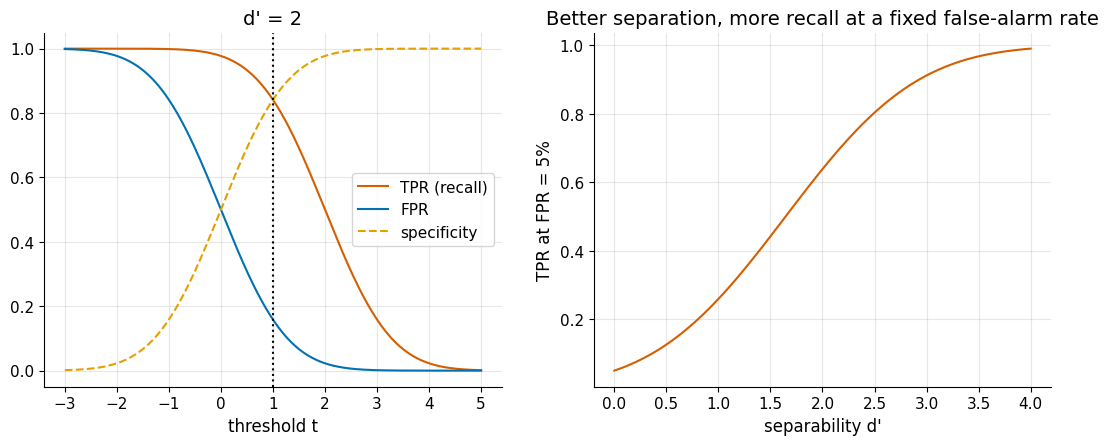

TPR at FPR 5% for d' = 0, 1, 2, 3: [0.05, 0.26, 0.639, 0.912]


In [5]:
ts = np.linspace(-3, 5, 400); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(ts, rates(ts)[0], color=HIGHLIGHT, label="TPR (recall)"); axes[0].plot(ts, rates(ts)[1], color=MAIN, label="FPR"); axes[0].plot(ts, 1 - rates(ts)[1], color=SIM, linestyle="--", label="specificity"); axes[0].axvline(1.0, color="black", linestyle=":"); axes[0].set_xlabel("threshold t"); axes[0].legend(); axes[0].set_title("d' = 2")
dd = np.linspace(0, 4, 100); t5 = stats.norm.isf(0.05); axes[1].plot(dd, stats.norm.sf(t5 - dd), color=HIGHLIGHT); axes[1].set_xlabel("separability d'"); axes[1].set_ylabel("TPR at FPR = 5%"); axes[1].set_title("Better separation, more recall at a fixed false-alarm rate")
plt.show(); print("TPR at FPR 5% for d' = 0, 1, 2, 3:", [round(float(stats.norm.sf(t5 - d)), 3) for d in (0, 1, 2, 3)]); assert abs(stats.norm.sf(t5 - 0) - 0.05) < 1e-12 and stats.norm.sf(t5 - 3) > 0.9

## 9. 3D visuals

### 9.1 Static: recall and false-alarm rate over (threshold, separability)
Two surfaces over the threshold $t$ and $d'$: the TPR rises with $d'$ at a fixed threshold, the FPR does not depend on $d'$ at all (the negatives' distribution is fixed): separation moves only the positives.

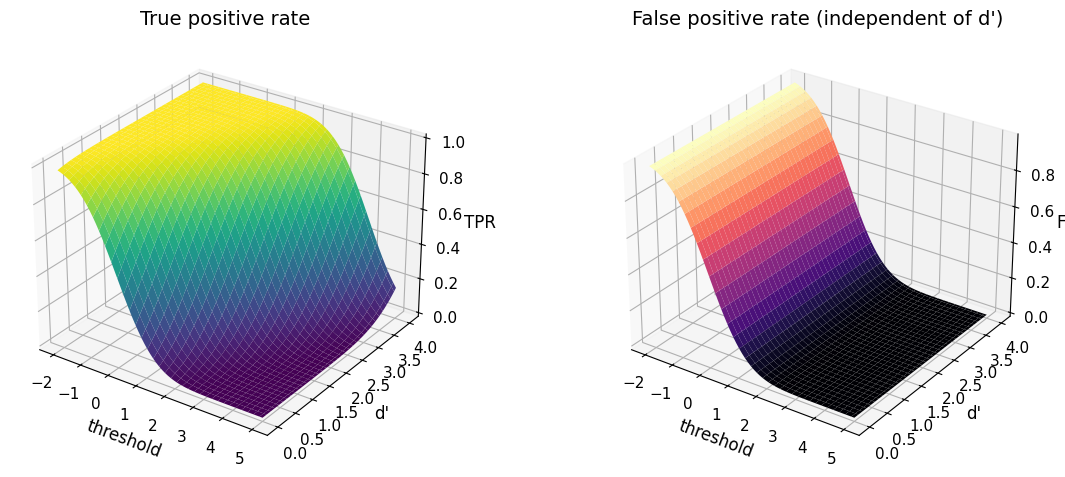

TPR at threshold 1: d' = 0: 0.159 d' = 2: 0.841 d' = 4: 0.9987


In [6]:
T1, D1 = np.meshgrid(np.linspace(-2, 5, 70), np.linspace(0, 4, 70)); TP_ = stats.norm.sf(T1 - D1); FP_ = stats.norm.sf(T1)
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(T1, D1, TP_, cmap="viridis", edgecolor="none"); ax.set_xlabel("threshold"); ax.set_ylabel("d'"); ax.set_zlabel("TPR"); ax.set_title("True positive rate"); ax.view_init(elev=28, azim=-55)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(T1, D1, FP_, cmap="magma", edgecolor="none"); ax.set_xlabel("threshold"); ax.set_ylabel("d'"); ax.set_zlabel("FPR"); ax.set_title("False positive rate (independent of d')"); ax.view_init(elev=28, azim=-55)
plt.show(); print("TPR at threshold 1: d' = 0:", round(float(stats.norm.sf(1.0)), 3), "d' = 2:", round(float(stats.norm.sf(-1.0)), 3), "d' = 4:", round(float(stats.norm.sf(-3.0)), 4)); assert np.allclose(FP_[0], FP_[-1]) and (np.diff(TP_, axis=0) >= -1e-12).all()

### 9.2 Interactive Plotly version of 9.1 (TPR)

In [7]:
fig = go.Figure(go.Surface(x=T1[0], y=D1[:, 0], z=TP_, colorscale="Viridis")); fig.update_layout(title="TPR over threshold and d'", width=760, height=560, scene=dict(xaxis_title="threshold", yaxis_title="d'", zaxis_title="TPR")); fig.show()

### 9.3 Static: precision over (threshold, prevalence)
For $d'=2$: PPV $=\dfrac{\pi\,\mathrm{TPR}}{\pi\,\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$. The surface is high for common positives and collapses for rare ones: at $\pi=0.001$ and $t=1$ the precision is about 0.5 %, and it rises only at thresholds so high that the recall is a tiny fraction of the positives.

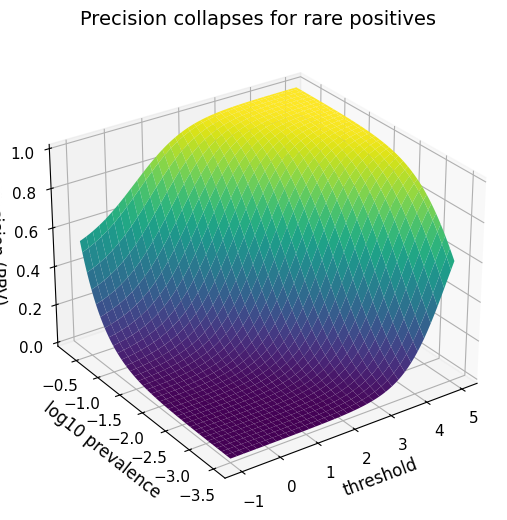

max PPV for prevalence 0.1%, 1%, 10% over t in [-1, 5]: [0.796, 0.975, 0.998]


In [8]:
T3, P3 = np.meshgrid(np.linspace(-1, 5, 70), np.logspace(-3.5, -0.3, 70)); tpr3 = stats.norm.sf(T3 - 2); fpr3 = stats.norm.sf(T3); PPV = P3 * tpr3 / (P3 * tpr3 + (1 - P3) * fpr3 + 1e-300)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(T3, np.log10(P3), PPV, cmap="viridis", edgecolor="none"); ax.set_xlabel("threshold"); ax.set_ylabel("log10 prevalence"); ax.set_zlabel("precision (PPV)"); ax.set_title("Precision collapses for rare positives"); ax.view_init(elev=28, azim=-125)
plt.show(); print("max PPV for prevalence 0.1%, 1%, 10% over t in [-1, 5]:", [round(float(ppv(stats.norm.sf(tt - 2), stats.norm.sf(tt), p_)), 3) for p_ in (0.001, 0.01, 0.1) for tt in [4.9]]); assert PPV[0, :40].max() < 0.1 and PPV[-1, 35] > 0.5

## 10. Simulation vs theory

### 10.1 The empirical confusion matrix matches the tail areas
Simulate 1,000,000 cases (prevalence 10 %, scores $N(0,1)$ and $N(2,1)$) and compare the empirical cells at thresholds 0, 1, 2 with the theoretical counts; deviations should be within a few binomial standard errors.

In [9]:
g = np.random.default_rng(1); N = 1_000_000; y = (g.random(N) < 0.1).astype(int); s = np.where(y == 1, g.normal(2, 1, N), g.normal(0, 1, N)); rows = []
for t_ in (0.0, 1.0, 2.0):
    Me = cm_emp(s, y, t_); Mt = cm_theory(t_, N=N); z = (Me - Mt) / np.sqrt(Mt * (1 - Mt / N) + 1e-9); rows.append((t_, Me[0, 0], Mt[0, 0], Me[1, 0], Mt[1, 0], np.abs(z).max()))
tb = pd.DataFrame(rows, columns=["t", "TP (sim)", "TP (theory)", "FP (sim)", "FP (theory)", "largest |z| over the four cells"]); print(tb.round(2).to_string(index=False)); assert tb["largest |z| over the four cells"].max() < 4

  t  TP (sim)  TP (theory)  FP (sim)  FP (theory)  largest |z| over the four cells
0.0     97773     97724.99    450274    450000.00                             0.88
1.0     84441     84134.47    143047    142789.73                             2.41
2.0     50362     50000.00     20668     20475.12                             1.66

### 10.2 Non-Gaussian and unequal-variance scores
Real scores are rarely Gaussian. For lognormal-like scores (positives $\mathrm{LogNormal}(0.8,0.5)$, negatives $\mathrm{LogNormal}(0,0.5)$) and for Gaussians with unequal variance (positives $N(2,1.5^2)$) the same definitions apply; only the closed forms change. Check the rates against the exact tail formulas.

In [10]:
g = np.random.default_rng(2); n = 500_000; sn = g.lognormal(0.0, 0.5, n); sp = g.lognormal(0.8, 0.5, n); t_ = 1.8
tpr_s, fpr_s = np.mean(sp > t_), np.mean(sn > t_); tpr_t, fpr_t = stats.lognorm.sf(t_, 0.5, scale=np.exp(0.8)), stats.lognorm.sf(t_, 0.5, scale=1.0)
print(f"lognormal scores at t = 1.8: TPR {tpr_s:.4f} (theory {tpr_t:.4f}), FPR {fpr_s:.4f} (theory {fpr_t:.4f})")
sp2 = g.normal(2, 1.5, n); sn2 = g.normal(0, 1, n); print(f"unequal variances at t = 1: TPR {np.mean(sp2 > 1):.4f} (theory {stats.norm.sf(1, 2, 1.5):.4f}), FPR {np.mean(sn2 > 1):.4f} (theory {stats.norm.sf(1):.4f})")
print("likelihood ratio f1/f0 at the threshold: equal-variance Gaussian increases with t; with unequal variances it is not monotone: at t = -3, 0, 3:", [round(float(stats.norm.pdf(tt, 2, 1.5) / stats.norm.pdf(tt, 0, 1)), 4) for tt in (-3, 0, 3)])
assert abs(tpr_s - tpr_t) < 0.003 and abs(fpr_s - fpr_t) < 0.003

lognormal scores at t = 1.8: TPR 0.6644 (theory 0.6644), FPR 0.1201 (theory 0.1199)
unequal variances at t = 1: TPR 0.7479 (theory 0.7475), FPR 0.1587 (theory 0.1587)
likelihood ratio f1/f0 at the threshold: equal-variance Gaussian increases with t; with unequal variances it is not monotone: at t = -3, 0, 3: [0.232, 0.2741, 48.0534]


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("tail areas: stats.norm.sf(t, mu, sigma) | threshold for a given FPR: stats.norm.isf(fpr, mu0, sigma) | counts: np.sum((score > t) & (y == 1)) ...")
print("PPV = pi tpr / (pi tpr + (1 - pi) fpr) | Wilson interval: statsmodels.stats.proportion.proportion_confint(k, n, method='wilson') | library: sklearn.metrics.confusion_matrix, ConfusionMatrixDisplay")
print("d' from rates: d' = Phi^-1(TPR) - Phi^-1(FPR) = ", round(float(stats.norm.isf(0.1587) * 0 + stats.norm.ppf(0.8413) - stats.norm.ppf(0.1587)), 3), "for TPR 0.8413 and FPR 0.1587 (signal-detection theory)")
assert abs(stats.norm.ppf(0.8413) - stats.norm.ppf(0.1587) - 2.0) < 0.002

tail areas: stats.norm.sf(t, mu, sigma) | threshold for a given FPR: stats.norm.isf(fpr, mu0, sigma) | counts: np.sum((score > t) & (y == 1)) ...
PPV = pi tpr / (pi tpr + (1 - pi) fpr) | Wilson interval: statsmodels.stats.proportion.proportion_confint(k, n, method='wilson') | library: sklearn.metrics.confusion_matrix, ConfusionMatrixDisplay
d' from rates: d' = Phi^-1(TPR) - Phi^-1(FPR) =  2.0 for TPR 0.8413 and FPR 0.1587 (signal-detection theory)


## 12. Real-world worked examples

---
### Example 1 (main): a fraud model on 100,000 transactions

**Scenario.** A fraud model gives each transaction a score; genuine transactions score $N(0,1)$ and fraudulent ones $N(2,1)$ ($d'=2$). **2 %** of the 100,000 daily transactions are fraudulent. The team flags every transaction with a score above $t$.

**Questions**
1. For $t=1$, $t=2$ and $t=3$: the expected confusion matrix, recall, precision and accuracy.
2. How many genuine customers are bothered for each fraud caught?
3. A model that flags nothing has what accuracy? Compare with the real model's accuracy.
4. What threshold gives a recall of exactly 80 %, and what is the precision there?

### 12.1 By hand
At $t=1$: $\mathrm{TPR}=1-\Phi(-1)=0.8413$, $\mathrm{FPR}=1-\Phi(1)=0.1587$. Per 100,000 transactions: $\mathrm{TP}=2000\cdot0.8413=1683$, $\mathrm{FN}=317$, $\mathrm{FP}=98000\cdot0.1587=15{,}553$, $\mathrm{TN}=82{,}447$. Precision $=1683/(1683+15{,}553)=0.098$: **about one alert in ten is a real fraud**, although the recall is 84 %. Accuracy $=(1683+82{,}447)/100{,}000=0.841$, below the 0.98 of a model that never flags.

In [12]:
N1, pi1 = 100_000, 0.02; rows = {}
for t_ in (1.0, 2.0, 3.0):
    Mt = cm_theory(t_, N=N1, pi=pi1); tp_, fp_ = rates(t_); rows[t_] = {"TP": Mt[0, 0], "FN": Mt[0, 1], "FP": Mt[1, 0], "TN": Mt[1, 1], "recall": tp_, "FPR": fp_, "precision": ppv(tp_, fp_, pi1), "accuracy": (Mt[0, 0] + Mt[1, 1]) / N1, "false alarms per fraud caught": Mt[1, 0] / Mt[0, 0]}
tb1 = pd.DataFrame(rows).T; print("Q1-Q2:"); print(tb1.round(3).to_string()); print(f"Q3: accuracy of a model that flags nothing: {1 - pi1:.3f}; the real model at t = 1 has {tb1.loc[1.0, 'accuracy']:.3f}, at t = 3 {tb1.loc[3.0, 'accuracy']:.3f}")
t80 = stats.norm.isf(0.8, 2, 1); tp8, fp8 = rates(t80); print(f"Q4: threshold for recall 80%: {t80:.4f}, FPR {fp8:.4f}, precision {ppv(tp8, fp8, pi1):.4f}, alerts per day {N1 * (pi1 * tp8 + (1 - pi1) * fp8):,.0f} of which real {N1 * pi1 * tp8:,.0f}")

Q1-Q2:
           TP        FN         FP         TN  recall    FPR  precision  accuracy  false alarms per fraud caught
1.0  1682.689   317.311  15548.215  82451.785   0.841  0.159      0.098     0.841                          9.240
2.0  1000.000  1000.000   2229.513  95770.487   0.500  0.023      0.310     0.968                          2.230
3.0   317.311  1682.689    132.290  97867.710   0.159  0.001      0.706     0.982                          0.417
Q3: accuracy of a model that flags nothing: 0.980; the real model at t = 1 has 0.841, at t = 3 0.982
Q4: threshold for recall 80%: 1.1584, FPR 0.1234, precision 0.1169, alerts per day 13,689 of which real 1,600


### 12.2 Asserts

In [13]:
assert abs(tb1.loc[1.0, "TP"] - 1682.6) < 0.5 and abs(tb1.loc[1.0, "FP"] - 15_553) < 5 and abs(tb1.loc[1.0, "precision"] - 0.0976) < 0.001 and all(tb1["accuracy"] < 0.98 + 0.01) and abs(t80 - 1.1584) < 0.001
assert abs(tb1[["TP", "FN", "FP", "TN"]].sum(axis=1) - N1).max() < 1e-6 and tb1["precision"].is_monotonic_increasing and tb1["recall"].is_monotonic_decreasing
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Simulate one day of 100,000 transactions 2,000 times and check the distribution of the number of false alarms and of the precision at $t=1$.

In [14]:
g = np.random.default_rng(3); R = 2000; fps = []; tps = []
for _ in range(R): yy = g.random(N1) < pi1; ss = np.where(yy, g.normal(2, 1, N1), g.normal(0, 1, N1)); pr = ss > 1.0; tps.append(np.sum(pr & yy)); fps.append(np.sum(pr & ~yy))
tps, fps = np.array(tps), np.array(fps); pre = tps / (tps + fps); print(f"false alarms per day: mean {fps.mean():.0f} (theory {tb1.loc[1.0, 'FP']:.0f}), SD {fps.std():.1f} (binomial SD {np.sqrt(98000 * 0.1587 * 0.8413):.1f}) | frauds caught: mean {tps.mean():.1f}, SD {tps.std():.1f} | precision: mean {pre.mean():.4f}, 95% of days between {np.quantile(pre, 0.025):.4f} and {np.quantile(pre, 0.975):.4f}"); assert abs(fps.mean() - tb1.loc[1.0, "FP"]) < 20 and abs(fps.std() / np.sqrt(98000 * 0.1587 * 0.8413) - 1) < 0.06

false alarms per day: mean 15552 (theory 15548), SD 112.9 (binomial SD 114.4) | frauds caught: mean 1684.0, SD 41.1 | precision: mean 0.0977, 95% of days between 0.0933 and 0.1023


### 12.4 Plots

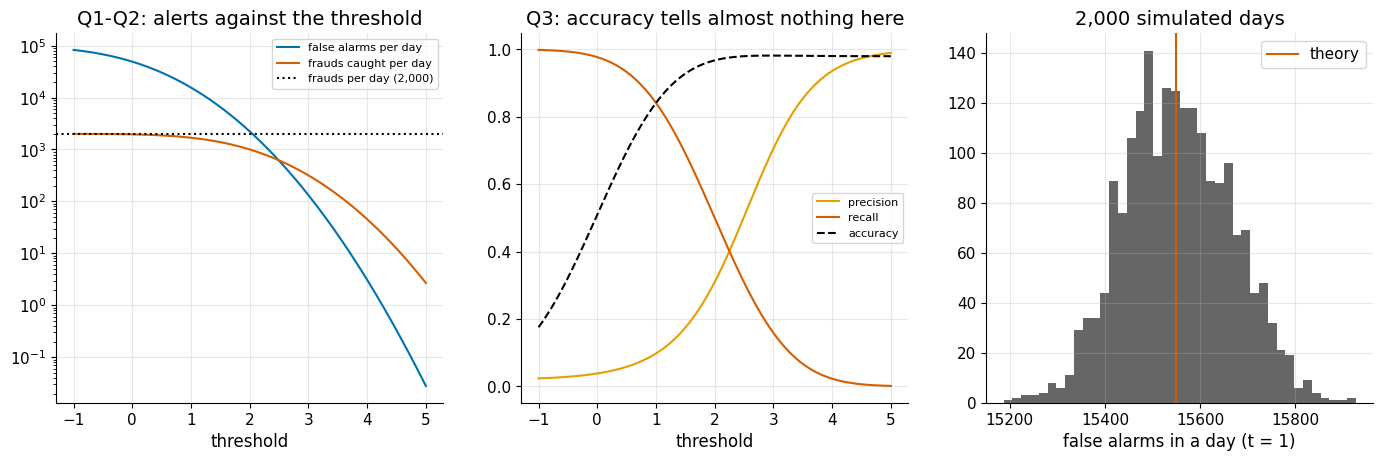

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); tg = np.linspace(-1, 5, 300); tpg, fpg = rates(tg); axes[0].semilogy(tg, N1 * (1 - pi1) * fpg, color=MAIN, label="false alarms per day"); axes[0].semilogy(tg, N1 * pi1 * tpg, color=HIGHLIGHT, label="frauds caught per day"); axes[0].axhline(N1 * pi1, color="black", linestyle=":", label="frauds per day (2,000)"); axes[0].legend(fontsize=8); axes[0].set_xlabel("threshold"); axes[0].set_title("Q1-Q2: alerts against the threshold")
axes[1].plot(tg, ppv(tpg, fpg + 1e-300, pi1), color=SIM, label="precision"); axes[1].plot(tg, tpg, color=HIGHLIGHT, label="recall"); axes[1].plot(tg, (N1 * pi1 * tpg + N1 * (1 - pi1) * (1 - fpg)) / N1, color="black", linestyle="--", label="accuracy"); axes[1].legend(fontsize=8); axes[1].set_xlabel("threshold"); axes[1].set_title("Q3: accuracy tells almost nothing here")
axes[2].hist(fps, bins=40, color=NEUTRAL); axes[2].axvline(tb1.loc[1.0, "FP"], color=HIGHLIGHT, label="theory"); axes[2].legend(); axes[2].set_xlabel("false alarms in a day (t = 1)"); axes[2].set_title("2,000 simulated days")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- With 2 % fraud, $d'=2$ and a threshold of 1, the day's 100,000 transactions give **1,683 true alerts, 15,548 false alerts, 317 missed frauds and 82,452 correct passes**: recall **84.1 %**, FPR 15.9 %, precision **9.8 %** (about **9.2 false alarms per fraud caught**) and accuracy **84.1 %**. A model that flags nothing has an accuracy of **98.0 %**: on rare events accuracy rewards doing nothing.
- Raising the threshold to 2 gives 1,000 hits, 2,230 false alarms (precision **31 %**, recall 50 %) and to 3 gives 317 hits and 132 false alarms (precision **70.6 %**, recall **15.9 %**, 0.4 false alarms per fraud): precision grows and recall falls, with no threshold that has both.
- To catch **80 %** of the frauds the threshold must be **1.158**: the FPR is 12.3 %, the team receives about **13,689 alerts a day, of which 1,600 are real (precision 11.7 %)**.
- 2,000 simulated days confirm the numbers: false alarms average 15,552 per day (theory 15,548) with an SD of 112.9 (binomial 114.4), and the precision of a single day lies between 0.0933 and 0.1023 in 95 % of days.
- **Decision.** Do not judge this classifier by accuracy; fix the review capacity first, then pick the threshold at which the number of alerts equals it (next lessons).

---
### Example 2: a screening test with uncertain sensitivity (estimation)

**Scenario.** A blood marker is used to screen for a disease. In a validation study 120 patients with the disease have marker values $N(5.0,1.2^2)$ and 480 healthy people $N(3.4,1.0^2)$. The cut-off for a positive screen is a marker value of 4.2 or more.

**Questions.** (1) Estimate the sensitivity and specificity with 95 % Wilson intervals. (2) What are the true values, and how often does the interval cover them (1,000 repeated studies)? (3) How large a validation study is needed to estimate the sensitivity to within $\pm0.05$?

In [16]:
g = np.random.default_rng(11); n1, n0 = 120, 480; d_pos = g.normal(5.0, 1.2, n1); d_neg = g.normal(3.4, 1.0, n0); cut = 4.2; tp_ = int(np.sum(d_pos >= cut)); tn_ = int(np.sum(d_neg < cut)); sens, spec = tp_ / n1, tn_ / n0; ws, wp = wilson(tp_, n1), wilson(tn_, n0)
true_se, true_sp = stats.norm.sf(cut, 5.0, 1.2), stats.norm.cdf(cut, 3.4, 1.0)
print(f"Q1: sensitivity {sens:.3f}, 95% Wilson interval {ws[0]:.3f} to {ws[1]:.3f} | specificity {spec:.3f}, interval {wp[0]:.3f} to {wp[1]:.3f}"); print(f"Q2: true sensitivity {true_se:.4f}, true specificity {true_sp:.4f}")
cs = cp = cws = 0
for _ in range(1000):
    k1 = np.sum(g.normal(5.0, 1.2, n1) >= cut); k0 = np.sum(g.normal(3.4, 1.0, n0) < cut); a = wilson(k1, n1); b = wilson(k0, n0); cs += a[0] <= true_se <= a[1]; cp += b[0] <= true_sp <= b[1]; w = k1 / n1 + np.array([-1, 1]) * 1.96 * np.sqrt(k1 / n1 * (1 - k1 / n1) / n1); cws += w[0] <= true_se <= w[1]
print(f"coverage over 1,000 studies: Wilson sensitivity {cs / 1000:.3f}, Wilson specificity {cp / 1000:.3f}, Wald sensitivity {cws / 1000:.3f}")
n_need = int(np.ceil(1.96 ** 2 * true_se * (1 - true_se) / 0.05 ** 2)); print(f"Q3: patients with the disease needed for a half-width of 0.05: {n_need} (the study had {n1})")

Q1: sensitivity 0.758, 95% Wilson interval 0.674 to 0.826 | specificity 0.806, interval 0.769 to 0.839
Q2: true sensitivity 0.7475, true specificity 0.7881


coverage over 1,000 studies: Wilson sensitivity 0.954, Wilson specificity 0.951, Wald sensitivity 0.956
Q3: patients with the disease needed for a half-width of 0.05: 291 (the study had 120)


### 12.5 Asserts

In [17]:
assert abs(true_se - stats.norm.sf(-0.6667)) < 1e-3 and ws[0] < sens < ws[1] and wp[0] < spec < wp[1] and abs(cs / 1000 - 0.95) < 0.025 and abs(cp / 1000 - 0.95) < 0.025
print("all checks passed")

all checks passed


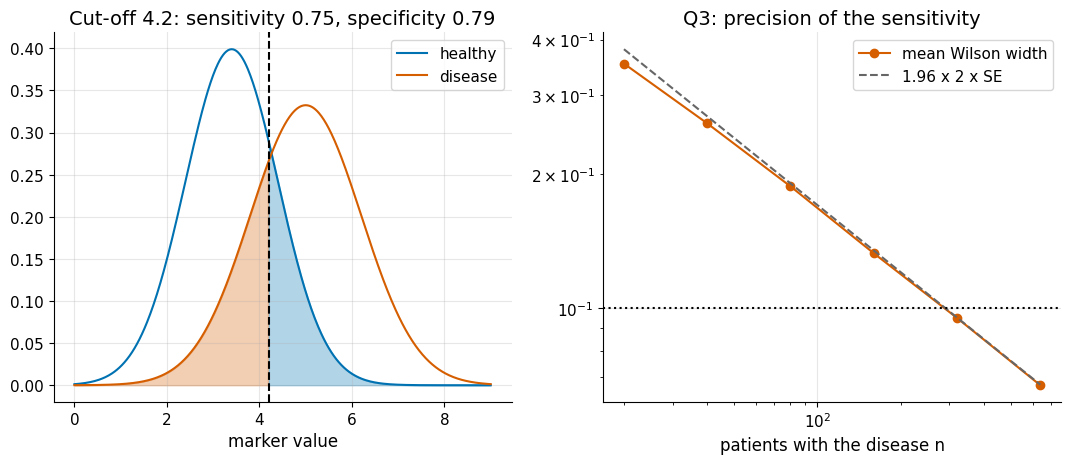

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); xg = np.linspace(0, 9, 500); axes[0].plot(xg, stats.norm.pdf(xg, 3.4, 1.0), color=MAIN, label="healthy"); axes[0].plot(xg, stats.norm.pdf(xg, 5.0, 1.2), color=HIGHLIGHT, label="disease"); axes[0].axvline(cut, color="black", linestyle="--"); axes[0].fill_between(xg, stats.norm.pdf(xg, 5.0, 1.2), where=xg < cut, color=HIGHLIGHT, alpha=0.3); axes[0].fill_between(xg, stats.norm.pdf(xg, 3.4, 1.0), where=xg >= cut, color=MAIN, alpha=0.3); axes[0].legend(); axes[0].set_xlabel("marker value"); axes[0].set_title(f"Cut-off 4.2: sensitivity {true_se:.2f}, specificity {true_sp:.2f}")
ns = np.array([20, 40, 80, 160, 320, 640]); wid = [np.mean([np.diff(wilson(np.random.default_rng(i).binomial(n, true_se), n))[0] for i in range(200)]) for n in ns]; axes[1].loglog(ns, wid, "o-", color=HIGHLIGHT, label="mean Wilson width"); axes[1].loglog(ns, 3.92 * np.sqrt(true_se * (1 - true_se) / ns), "--", color=NEUTRAL, label="1.96 x 2 x SE"); axes[1].axhline(0.1, color="black", linestyle=":"); axes[1].legend(); axes[1].set_xlabel("patients with the disease n"); axes[1].set_title("Q3: precision of the sensitivity")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The study of 120 patients and 480 healthy people gives a sensitivity of **0.758** (95 % Wilson interval **0.674 to 0.826**) and a specificity of **0.806** (**0.769 to 0.839**) at the cut-off 4.2. The true values are **0.7475** and **0.7881**, both inside the intervals.
- Over 1,000 repeated studies the Wilson intervals cover the truth **95.4 %** (sensitivity) and **95.1 %** (specificity) of the time; the plain Wald interval for the sensitivity covers 95.6 %, because the proportion is far from 0 and 1 here (the Wilson interval is the safer choice near the extremes).
- To estimate the sensitivity to within $\pm0.05$ one needs about **291 diseased patients**, 2.4 times as many as the study had: the sensitivity is the least precisely known quantity because it rests on 120 cases.
- **Decision.** Report sensitivity and specificity with intervals, and size a diagnostic study by the number of *positives*, not the total number of participants.

---
### Example 3: real score distributions (SMS spam)

**Scenario.** Module 09 built a naive Bayes spam filter on the SMS Spam Collection (5,574 messages, 747 spam). Its score is the log-odds of spam. We recompute the scores on the held-out 20 % and read the confusion matrices at several thresholds. The two class-conditional score distributions are far from Gaussian.

**Questions.** (1) What do the score distributions of ham and spam look like (medians, spread, skewness)? (2) The confusion matrix at the default threshold 0, at 5 and at -5, with recall, FPR and precision. (3) How well does the Gaussian approximation (matching means and SDs of the two groups) predict the FPR and TPR at these thresholds?

In [19]:
import re
from collections import Counter
from scipy import sparse
raw = pd.read_csv("../../module_09_probabilistic_models/data/SMSSpamCollection.tsv", sep="\t", header=None, names=["label", "text"], encoding="utf-8", quoting=3); y_all = (raw["label"] == "spam").astype(int).to_numpy(); texts = raw["text"].tolist(); tok = lambda s: re.findall(r"[a-z0-9']+|[£$!?]", s.lower())
g = np.random.default_rng(0); perm = g.permutation(len(texts)); ntr = int(0.8 * len(texts)); itr, ite = perm[:ntr], perm[ntr:]; cnt = Counter(w for i in itr for w in tok(texts[i])); vocab = {w: k for k, (w, c) in enumerate(sorted((w, c) for w, c in cnt.items() if c >= 2))}; V = len(vocab)
def bow(idx):
    rows, cols, vals = [], [], []
    for r, i in enumerate(idx):
        for w, c in Counter(tok(texts[i])).items():
            if w in vocab: rows.append(r); cols.append(vocab[w]); vals.append(c)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(idx), V), dtype=float)
Xtr, Xte = bow(itr), bow(ite); ytr, yte = y_all[itr], y_all[ite]; fc = np.vstack([np.asarray(Xtr[ytr == c].sum(axis=0)).ravel() for c in (0, 1)]); lt = np.log((fc + 1) / (fc.sum(axis=1, keepdims=True) + V)); sc_te = np.asarray(Xte @ (lt[1] - lt[0])).ravel() + np.log(ytr.mean() / (1 - ytr.mean()))
s_h, s_s = sc_te[yte == 0], sc_te[yte == 1]; print(f"test messages {len(yte)}: ham {len(s_h)}, spam {len(s_s)}"); print(f"Q1: ham scores: median {np.median(s_h):.1f}, IQR {np.quantile(s_h, 0.25):.1f} to {np.quantile(s_h, 0.75):.1f}, skewness {stats.skew(s_h):.2f} | spam scores: median {np.median(s_s):.1f}, IQR {np.quantile(s_s, 0.25):.1f} to {np.quantile(s_s, 0.75):.1f}, skewness {stats.skew(s_s):.2f}")
rows = {}
for t_ in (-5.0, 0.0, 5.0):
    Me = cm_emp(sc_te, yte, t_); tp_e, fp_e = Me[0, 0] / Me[0].sum(), Me[1, 0] / Me[1].sum(); tp_g, fp_g = stats.norm.sf(t_, s_s.mean(), s_s.std()), stats.norm.sf(t_, s_h.mean(), s_h.std()); rows[t_] = {"TP": Me[0, 0], "FN": Me[0, 1], "FP": Me[1, 0], "TN": Me[1, 1], "recall": tp_e, "FPR": fp_e, "precision": Me[0, 0] / max(Me[0, 0] + Me[1, 0], 1), "recall (Gaussian fit)": tp_g, "FPR (Gaussian fit)": fp_g}
tb3 = pd.DataFrame(rows).T; print("Q2-Q3:"); print(tb3.round(4).to_string())

test messages 1115: ham 974, spam 141
Q1: ham scores: median -12.8, IQR -21.1 to -8.5, skewness -3.09 | spam scores: median 31.5, IQR 11.6 to 45.8, skewness -0.09
Q2-Q3:
         TP    FN    FP     TN  recall     FPR  precision  recall (Gaussian fit)  FPR (Gaussian fit)
-5.0  137.0   4.0  86.0  888.0  0.9716  0.0883     0.6143                 0.9522              0.1856
 0.0  131.0  10.0   5.0  969.0  0.9291  0.0051     0.9632                 0.9237              0.0982
 5.0  126.0  15.0   1.0  973.0  0.8936  0.0010     0.9921                 0.8839              0.0456


### 12.6 Asserts

In [20]:
assert len(s_s) + len(s_h) == len(yte) and tb3.loc[0.0, "recall"] > 0.88 and tb3.loc[0.0, "FPR"] < 0.02 and tb3["recall"].is_monotonic_decreasing and abs(tb3.loc[0.0, "FPR (Gaussian fit)"] - tb3.loc[0.0, "FPR"]) > 0.005
print("all checks passed")

all checks passed


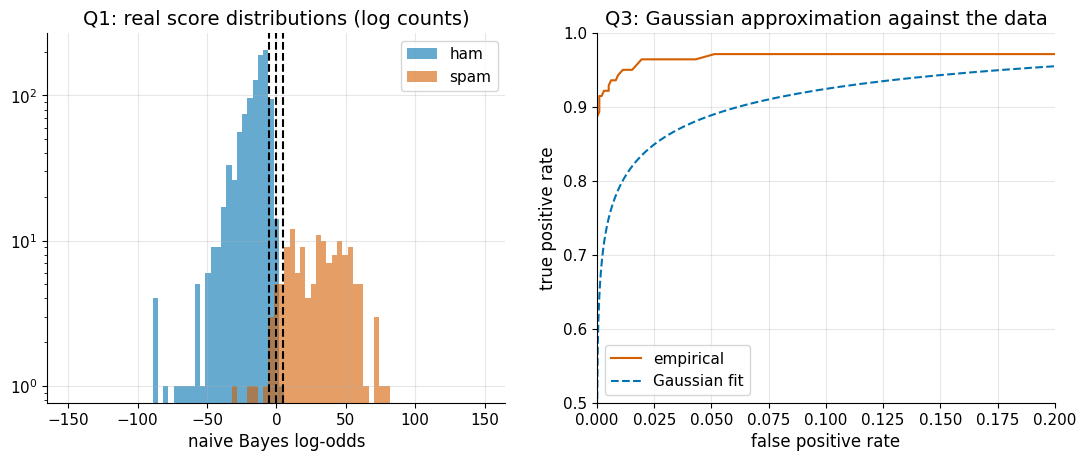

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); bins = np.linspace(-150, 150, 80); axes[0].hist(s_h, bins=bins, color=MAIN, alpha=0.6, label="ham"); axes[0].hist(s_s, bins=bins, color=HIGHLIGHT, alpha=0.6, label="spam"); axes[0].set_yscale("log"); [axes[0].axvline(t_, color="black", linestyle="--") for t_ in (-5, 0, 5)]; axes[0].legend(); axes[0].set_xlabel("naive Bayes log-odds"); axes[0].set_title("Q1: real score distributions (log counts)")
tg = np.linspace(-40, 60, 300); axes[1].plot([np.mean(s_h > t_) for t_ in tg], [np.mean(s_s > t_) for t_ in tg], color=HIGHLIGHT, label="empirical"); axes[1].plot(stats.norm.sf(tg, s_h.mean(), s_h.std()), stats.norm.sf(tg, s_s.mean(), s_s.std()), color=MAIN, linestyle="--", label="Gaussian fit"); axes[1].set_xlim(0, 0.2); axes[1].set_ylim(0.5, 1); axes[1].legend(); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("Q3: Gaussian approximation against the data")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The 1,115 test messages (974 ham, 141 spam) give two very different score distributions: ham scores have a median of **-12.8** and a strongly **left-skewed** tail (skewness **-3.1**); spam scores have a median of 31.5 and are nearly symmetric (skewness -0.09).
- At the default threshold 0 the filter has **131 hits, 10 misses, 5 false alarms and 969 correct passes**: recall **92.9 %**, FPR **0.51 %**, precision **96.3 %**. At -5 recall rises to 97.2 % but the FPR to 8.8 % (precision 61 %); at +5 the FPR falls to 0.10 % (1 false alarm) and recall to 89.4 %.
- **The Gaussian approximation is badly wrong in the tail that matters:** matching the means and SDs of the two groups predicts an FPR of **9.8 %** at threshold 0 (true 0.51 %), 18.6 % at -5 (true 8.8 %) and 4.6 % at +5 (true 0.10 %), because the ham distribution is skewed and its SD is dominated by the long left tail.
- **Decision.** Estimate TPR and FPR from the empirical distributions (or a fitted skewed distribution), not from two Gaussians, and look at the confusion matrices at the thresholds you may actually use.

---
### Example 4: the same classifier at different prevalences

**Scenario.** A content-moderation classifier has $\mathrm{TPR}=0.90$ and $\mathrm{FPR}=0.02$ (a fixed threshold, $d'\approx3.6$ for equal-variance Gaussians). It is deployed on streams where the share of harmful items is 50 %, 10 %, 1 %, 0.1 % and 0.01 %, with 1,000,000 items per day.

**Questions.** (1) Expected confusion matrix, precision and accuracy at each prevalence. (2) Reviews needed per harmful item found. (3) At which prevalence does the precision fall below 50 %?

In [22]:
prevs = [0.5, 0.1, 0.01, 0.001, 0.0001]; N4 = 1_000_000; tp4, fp4 = 0.90, 0.02; rows = {}
for p in prevs: Mt = np.array([[N4 * p * tp4, N4 * p * (1 - tp4)], [N4 * (1 - p) * fp4, N4 * (1 - p) * (1 - fp4)]]); rows[p] = {"TP": Mt[0, 0], "FP": Mt[1, 0], "FN": Mt[0, 1], "TN": Mt[1, 1], "precision": ppv(tp4, fp4, p), "accuracy": (Mt[0, 0] + Mt[1, 1]) / N4, "reviews per harmful item found": (Mt[0, 0] + Mt[1, 0]) / Mt[0, 0], "NPV": Mt[1, 1] / (Mt[1, 1] + Mt[0, 1])}
tb4 = pd.DataFrame(rows).T; print(tb4.round(4).to_string()); p50 = tp4 * 0 + fp4 * 1.0 / (tp4 + fp4); print(f"Q3: precision = 50% when pi / (1 - pi) = FPR / TPR, i.e. pi = {p50:.4f}: prevalence {p50:.2%}")

              TP       FP       FN        TN  precision  accuracy  reviews per harmful item found     NPV
0.5000  450000.0  10000.0  50000.0  490000.0     0.9783    0.9400                          1.0222  0.9074
0.1000   90000.0  18000.0  10000.0  882000.0     0.8333    0.9720                          1.2000  0.9888
0.0100    9000.0  19800.0   1000.0  970200.0     0.3125    0.9792                          3.2000  0.9990
0.0010     900.0  19980.0    100.0  979020.0     0.0431    0.9799                         23.2000  0.9999
0.0001      90.0  19998.0     10.0  979902.0     0.0045    0.9800                        223.2000  1.0000
Q3: precision = 50% when pi / (1 - pi) = FPR / TPR, i.e. pi = 0.0217: prevalence 2.17%


### 12.7 Asserts

In [23]:
assert abs(tb4.loc[0.5, "precision"] - 0.9 / 0.92) < 1e-9 and tb4.loc[0.001, "precision"] < 0.05 and abs(p50 - 0.02 / 0.92) < 1e-12 and tb4["precision"].is_monotonic_decreasing and abs(ppv(tp4, fp4, p50) - 0.5) < 1e-9
print("all checks passed")

all checks passed


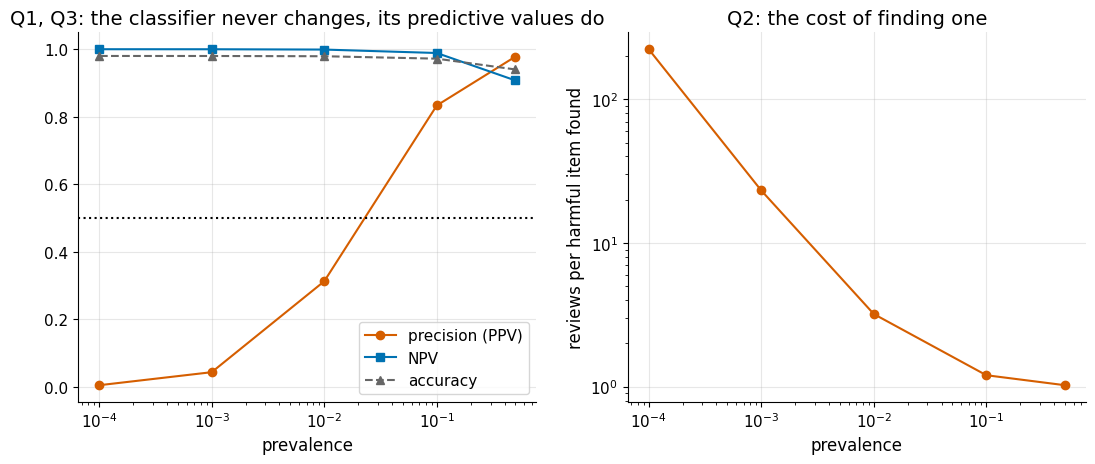

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(prevs, tb4["precision"], "o-", color=HIGHLIGHT, label="precision (PPV)"); axes[0].semilogx(prevs, tb4["NPV"], "s-", color=MAIN, label="NPV"); axes[0].semilogx(prevs, tb4["accuracy"], "^--", color=NEUTRAL, label="accuracy"); axes[0].axhline(0.5, color="black", linestyle=":"); axes[0].legend(); axes[0].set_xlabel("prevalence"); axes[0].set_title("Q1, Q3: the classifier never changes, its predictive values do")
axes[1].loglog(prevs, tb4["reviews per harmful item found"], "o-", color=HIGHLIGHT); axes[1].set_xlabel("prevalence"); axes[1].set_ylabel("reviews per harmful item found"); axes[1].set_title("Q2: the cost of finding one")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- With the same classifier (recall 0.90, FPR 0.02) the **precision is 97.8 % at prevalence 50 %, 83.3 % at 10 %, 31.3 % at 1 %, 4.3 % at 0.1 % and 0.45 % at 0.01 %**; accuracy stays near 0.94 to 0.98 in every case and the NPV above 0.9. For every harmful item found the reviewers look at 1.02, 1.2, 3.2, **23.2** and **223** items.
- The precision drops below 50 % when the prevalence falls under **2.17 %** (where $\pi/(1-\pi)=\mathrm{FPR}/\mathrm{TPR}$): below that, most alerts are false whatever the recall.
- **Decision.** Report precision *for the deployment prevalence* (and re-measure it when the mix changes); at low prevalence use a higher threshold or a two-stage process in which a cheaper second check removes false alarms.

## 13. Where it is used

### Statistics
- **Type I and type II errors, power and significance** of every test; **signal detection theory** ($d'$) in psychophysics; **diagnostic accuracy studies** in medicine (STARD reporting, sensitivity and specificity with confidence intervals).

### Data science
- **Fraud, churn, credit and abuse scoring**, spam and moderation filters, quality inspection, lead scoring; **capacity planning of review teams** from the expected number of alerts; threshold choice with the business (next lessons).

### ML and AI
- The **output layer** of every classifier (a score or logit and a threshold), **evaluation of safety classifiers** for language models, red-teaming metrics, **anomaly and out-of-distribution detectors** (09_05), and calibration of probabilities (10_06).

## 14. Common pitfalls and misconceptions

- **Reading accuracy on rare events:** a model that flags nothing has accuracy $1-\pi$ (Example 1).
- **Quoting TPR and FPR without the prevalence:** they say nothing about how many alerts are real; precision depends on $\pi$ (Example 4).
- **Treating the threshold as fixed:** the confusion matrix is a function of the threshold; always say at which one.
- **Estimating rates from few positives:** with 20 positives the recall has an interval of $\pm0.15$ (Example 2); report Wilson intervals.
- **Assuming Gaussian scores:** real score distributions are skewed and heavy-tailed; the Gaussian approximation can misstate the FPR several-fold in the tails (Example 3).
- **Mixing the two kinds of rate:** TPR and FPR condition on the true class (columns of rates), PPV and NPV condition on the prediction.
- **Evaluating on the training set or on a different population:** prevalence and score distributions shift (09_14); recompute the matrix on representative data.

## 15. Exercises

1. For scores $N(0,1)$ (negatives) and $N(1.5,1)$ (positives) and threshold 0.75, compute TPR, FPR and, for prevalence 5 % and 10,000 cases, the four counts.
2. A test has sensitivity 95 % and specificity 90 %. For prevalence 1 % compute PPV and NPV.
3. How large must $d'$ be for $\mathrm{TPR}=\mathrm{TNR}=0.95$ at the midpoint threshold?
4. For 40 positives of which 34 are detected, give the Wald and Wilson 95 % intervals for the recall.
5. A classifier flags 5 % of all cases; the prevalence is 2 % and recall 80 %. What are the precision and the FPR?
6. (Harder) Show that scaling all scores by a positive constant or applying $\log$ changes neither the TPR-FPR pairs nor the PPV at matching thresholds.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Depends on prevalence? |
|---|---|---|
| TPR (recall, sensitivity) | $P(S>t\mid1)=1-F_1(t)$ | no |
| FPR | $P(S>t\mid0)=1-F_0(t)$ | no |
| Specificity | $1-\mathrm{FPR}$ | no |
| PPV (precision) | $\frac{\pi\mathrm{TPR}}{\pi\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$ | **yes** |
| NPV | $\frac{(1-\pi)(1-\mathrm{FPR})}{(1-\pi)(1-\mathrm{FPR})+\pi(1-\mathrm{TPR})}$ | **yes** |
| Accuracy | $\pi\mathrm{TPR}+(1-\pi)(1-\mathrm{FPR})$ | **yes** |
| $d'$ | $(\mu_1-\mu_0)/\sigma$ | no |
| Wilson interval | see 5.4 | |

## Solutions

In [25]:
tp1, fp1 = rates(0.75, mu0=0.0, mu1=1.5); Mx = cm_theory(0.75, N=10_000, pi=0.05, mu0=0.0, mu1=1.5); print(f"1: TPR {tp1:.4f}, FPR {fp1:.4f}; counts TP {Mx[0, 0]:.1f}, FN {Mx[0, 1]:.1f}, FP {Mx[1, 0]:.1f}, TN {Mx[1, 1]:.1f}")
se, sp_, pr = 0.95, 0.90, 0.01; print(f"2: PPV = {pr * se / (pr * se + (1 - pr) * (1 - sp_)):.4f}, NPV = {(1 - pr) * sp_ / ((1 - pr) * sp_ + pr * (1 - se)):.4f}")
print(f"3: Phi(d'/2) = 0.95 -> d' = {2 * stats.norm.ppf(0.95):.4f}")
print(f"4: recall 34/40 = 0.85: Wald {np.round(0.85 + np.array([-1, 1]) * 1.96 * np.sqrt(0.85 * 0.15 / 40), 3)}, Wilson {np.round(wilson(34, 40), 3)}")
tpr5, flag, pi5 = 0.8, 0.05, 0.02; fpr5 = (flag - pi5 * tpr5) / (1 - pi5); print(f"5: FPR = (0.05 - 0.02 x 0.8) / 0.98 = {fpr5:.4f}; precision = {pi5 * tpr5 / flag:.3f}")
g = np.random.default_rng(9); s_ = np.where(g.random(5000) < 0.3, g.normal(1.5, 1, 5000), g.normal(0, 1, 5000)); y_ = (s_ > 0.9).astype(int); sc1 = np.exp(s_); print("6: counts at matching thresholds are identical after a monotone transformation:", np.array_equal(cm_emp(s_, y_, 0.7), cm_emp(np.log(sc1), y_, 0.7)), np.array_equal(cm_emp(s_, y_, 0.7), cm_emp(sc1, y_, np.exp(0.7))), np.array_equal(cm_emp(s_, y_, 0.7), cm_emp(5 * s_, y_, 3.5)))
assert abs(tp1 - 0.7734) < 1e-3 and abs(fp1 - 0.2266) < 1e-3 and abs(fpr5 - 0.03469) < 1e-3

1: TPR 0.7734, FPR 0.2266; counts TP 386.7, FN 113.3, FP 2153.0, TN 7347.0
2: PPV = 0.0876, NPV = 0.9994
3: Phi(d'/2) = 0.95 -> d' = 3.2897
4: recall 34/40 = 0.85: Wald [0.739 0.961], Wilson [0.709 0.929]
5: FPR = (0.05 - 0.02 x 0.8) / 0.98 = 0.0347; precision = 0.320
6: counts at matching thresholds are identical after a monotone transformation: True True True


**1.** TPR $=1-\Phi(0.75-1.5)=$ **0.7734**, FPR $=1-\Phi(0.75)=$ **0.2266**; with 500 positives and 9,500 negatives: TP **387**, FN **113**, FP **2,153**, TN **7,347**.

**2.** PPV $=\dfrac{0.01\cdot0.95}{0.01\cdot0.95+0.99\cdot0.10}=$ **0.0876** and NPV $=$ **0.9994**: a positive screen is a real case less than one time in eleven.

**3.** $\Phi(d'/2)=0.95$ gives $d'=2\cdot1.645=$ **3.29**.

**4.** Recall $34/40=0.85$: Wald **(0.739, 0.961)**, Wilson **(0.709, 0.929)**: the Wald interval is too optimistic at the top and too wide at the bottom.

**5.** $\mathrm{TP}=0.02\cdot0.8=1.6\,\%$, so $\mathrm{FPR}=(0.05-0.016)/0.98=$ **0.0347**, and precision $=1.6/5=$ **0.32**.

**6.** The counts are identical (True, True, True) after multiplying the scores by 5, taking $\exp$ or $\log$ and transforming the threshold the same way: only the ranking of scores matters.